# Homework 6 - PHY 512

Élyse D'Aoust

261335942

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Question 1 - An improved version of RANDU

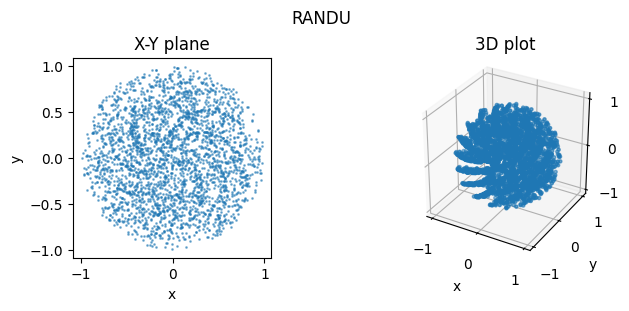

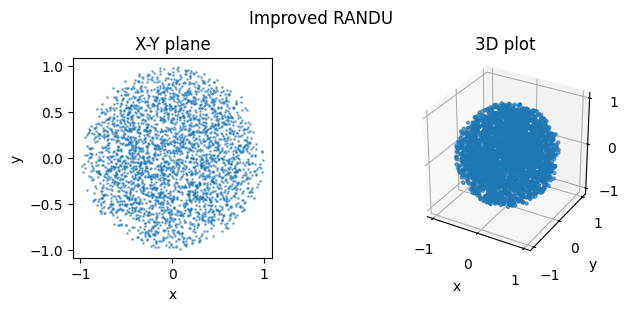

In [204]:
# Implementation of an LCG from class solutions (taken from Wikipedia)
def lcg(modulus, a, c, seed):
    """Linear congruential generator."""
    while True:
        seed = (a * seed + c) % modulus
        yield seed

# Improved RANDU
def randu_updated(random_vals, y, ind_new, m, n_coords):
    j = np.copy(random_vals[:100]) # buffer array (first 100 values generated with lcg)
    vals = np.zeros(n_coords) # array that will contain the random values (for the coordinates)
    for i in range(n_coords):
        k = int(100*y/m) # calculate index k
        vals[i] = j[k] # get value at index k in the buffer array
        y = j[k] # set y = j_k
        j[k] = random_vals[ind_new] # repopulate buffer array at that index with the next random number in the random_vals array (after y)
        ind_new = ind_new + 1 # increment index of the next random number in random_vals array
    return vals

def get_cartesian_coords(random_numbers):
    # Offsetting the chosen spherical coordinates from the random number array by 1 for each coordinate
    phi = 2*np.pi*random_numbers[:-2] # phi between 0 and 2pi
    mu = 2*random_numbers[1:-1] - 1 # for cos(theta) between -1 and 1
    r = random_numbers[2:]**(1/3)
    theta = np.arccos(mu) # since mu = cos(theta)

    # Calculate x, y and z coordinates from coordinate transformation (spherical --> cartesian)
    x = r*np.sin(theta)*np.cos(phi)
    y = r*np.sin(theta)*np.sin(phi)
    z = r*mu
    return x, y, z

# Parameters for lcg
seed = 500
m = 2**31
a = 65539
c = 0

n_coords = 3002 # 3000 coordinate points, with 2 extra points to offset the subset chosen for each random coordinate

# Get x, y, z coordinates for both methods

# RANDU
randu_vals = np.fromiter(lcg(m, a, c, seed), float, count = n_coords)/m # Divide by m to get values between 0 and 1
x_randu, y_randu, z_randu = get_cartesian_coords(randu_vals) # get cartesian coordinates using random numbers

# Improved RANDU
random_vals = np.fromiter(lcg(m, a, c, seed), float, count = n_coords + 101) # count is n_coords+101 to account for the 100 values in the buffer array and the initial y value
y = random_vals[100] # pick 101st value in the array of random numbers (will be the first value after what will be used as the buffer array)
ind_new = 100+1 # index of the next random number in the random_vals array

# Get random numbers, and divide by m to make all values between 0 and 1
improved_randu_vals = randu_updated(random_vals, y, ind_new, m, n_coords)/m
x, y, z = get_cartesian_coords(improved_randu_vals) # get cartesian coordinates using random numbers

# Plotting (RANDU)
fig = plt.figure(figsize=(10,3), layout="constrained")

# 2D plot (x-y plane)
ax1 = fig.add_subplot(132)
ax1.scatter(x_randu, y_randu, s=1, alpha=0.5)
ax1.set_aspect('equal')
ax1.set_title('X-Y plane')
ax1.set_xlabel('x')
ax1.set_ylabel('y')

# 3D plot
ax2 = fig.add_subplot(133, projection='3d')
ax2.scatter(x_randu, y_randu, z_randu, marker='.')
ax2.set_aspect('equal')
ax2.set_title('3D plot')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_zlabel('z')

fig.suptitle('RANDU', x=0.65)
plt.show()

# Plotting (improved RANDU)
fig = plt.figure(figsize=(10,3), layout="constrained")

# 2D plot (x-y plane)
ax1 = fig.add_subplot(132)
ax1.scatter(x, y, s=1, alpha=0.5)
ax1.set_aspect('equal')
ax1.set_title('X-Y plane')
ax1.set_xlabel('x')
ax1.set_ylabel('y')

# 3D plot
ax2 = fig.add_subplot(133, projection='3d')
ax2.scatter(x, y, z, marker='.')
ax2.set_aspect('equal')
ax2.set_title('3D plot')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_zlabel('z')

fig.suptitle('Improved RANDU', x=0.65)
plt.show()

From the two plots above, we can clearly see a difference between the two methods. Indeed, for the RANDU method, some structure can be observed in both the x-y plane plot and the 3D plot. A spiral shape can be observed in the 3D plot, and a faint outline of a spiral is also seen in the 2D plot, although less obvious. This suggests that the successively generated random numbers using the RANDU method are fairly correlated, leading to visible patterns observed when plotting what should resemble a random distribution. On the other hand, the improved RANDU method seems to produce much better results. Indeed, it can be observed in both the 2D and 3D plots that the points seem more uniformly distributed throughout the sphere (there are no regions that seem obviously more dense). This means that this improved method produces random numbers that are a lot less correlated (in this case, we know that it at least reduces the correlations between successive random numbers).

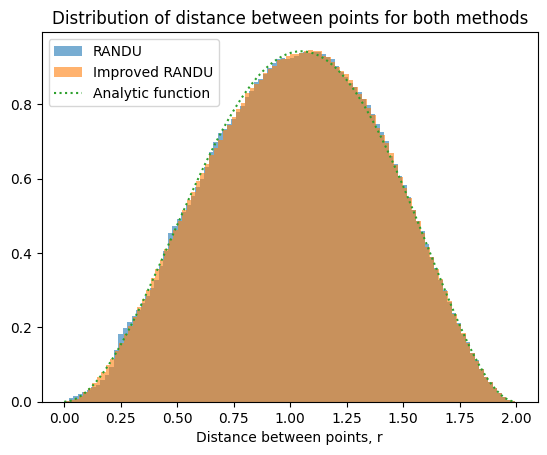

In [194]:
import scipy

# Histogram plotting code taken from class solutions
# Function that takes the x values and plots a histogram comparing to the analytic function func
def plot_distribution(x1, x2, func):
    plt.clf()
    plt.hist(x1, density=True, bins=100, alpha=0.6, label='RANDU')
    plt.hist(x2, density=True, bins=100, alpha=0.6, label='Improved RANDU')
    xx = np.linspace(np.min([min(x1), min(x2)]), np.max([max(x1), max(x2)]), 100)
    plt.plot(xx, func(xx),':', label='Analytic function')
    plt.xlabel('Distance between points, r')
    plt.title('Distribution of distance between points for both methods')
    plt.legend()
    plt.show()

# Analytic distribution of distances
def p(r):
    return ((3/16)*(r**2)*(4+r)*((2-r)**2))

# Get arrays with the x, y and z coordinates as columns
coord_points_randu = np.column_stack((x_randu, y_randu, z_randu))
coord_points_improved_randu = np.column_stack((x, y, z))

# Calculate distance between points
distance_randu = scipy.spatial.distance.pdist(coord_points_randu)
distance_improved_randu = scipy.spatial.distance.pdist(coord_points_improved_randu)

# Plot
plot_distribution(distance_randu, distance_improved_randu, p)

Looking at the histogram, we can again observe a pretty clear difference between both methods. Using the RANDU method to generate random numbers, we can see that the histogram of the distance between points exhibits a pattern, with observable oscillations around the prediction from the analytic function (especially on the left side of the function). On the other hand, the improved RANDU method seems to follow the expected distribution a lot more closely, with no obvious trend or pattern (it reproduces the analytic distance distribution much better). Since shuffling around the numbers generated with RANDU improves the method's reproduction of the analytic function's prediction, we can see that consecutively generated numbers using RANDU seem generally correlated, however by randomly picking some of these values we obtain a much better outcome.

## Question 2 - Ising model

Part a)

For this part, let's write a code that sets up a lattice of spins (represented as a 1D array), all being spin up (s = +1) in the first configuration. Then, we will pick one of the spins in the lattice at random, and calculate the change in energy if it were to be flipped (based on the spins of its neighbours). Then, using a randomly generated number between 0 and 1 (which we will name u), we will accept the spin flip if we have $u \leq \frac{f(E')}{f(E)}$, where $E$ is the current energy, $E'$ is the resulting energy if we did the spin flip, and the function $f()$ represents the Boltzmann distribution. Given that $\frac{e^{-E'/k_BT}}{e^{-E/k_BT}} = e^{-\Delta E/k_BT}$, where $\Delta E = E' - E$, we can write this as $u \leq f(\Delta E)$. Otherwise, the proposed spin flip is rejected, and the next configuration remains unchanged. After each step, we will calculate the magnetization of the new configuration, and add it to the magnetization chain (an array containing all of the magnetization values).

In [206]:
seed = 500
rng = np.random.default_rng(seed)

In [207]:
# Boltzmann distribution
def f(E, kB_T):
    return np.exp(-E/(kB_T))

# Calculate sum of up, down, left and right neighbours
def sum_neighbour_spin(spin_arr, n_rows, n_columns, s_i_index):
    r = s_i_index // n_columns # which row s_i is found in
    c = s_i_index % n_columns # which column s_i is found it

    s_up = ((r-1) % n_rows)*n_columns + c # index of updwards neighbour
    s_down = ((r+1) % n_rows)*n_columns + c # index of downwards neighbour
    s_right = r*n_columns + ((c-1) % n_columns) # index of right neighbour
    s_left = r*n_columns + ((c+1) % n_columns) # index of left neighbour
    neighbour_sum = (spin_arr[s_up] + spin_arr[s_down] + spin_arr[s_right] + spin_arr[s_left]) # compute sum of spins
    return neighbour_sum

# Calculate the total energy of a configuration
def calculate_energy(s, n_rows, n_columns):
    # sums all pairs of neighbour spins ONCE
    E = 0
    for i in range(n_rows*n_columns):
        r = i // n_columns # which row the current s_i is found in
        c = i % n_columns # which column the current s_i is found it

        # Calculate indices for the right and down neighbours of s_i
        right = r*n_columns + ((c+1) % n_columns)
        down = ((r+1) % n_rows)*n_columns + c

        # Add the two products to the sum (based on equation 2 given in the problem)
        E = E + s[i]*s[right] + s[i]*s[down]
    return -E

# Function to get the chain of magnetizations from one configuration to the next
def get_M(n, N, n_grids, kB_T):
    M = np.zeros(n_grids) # initialize chain of magnetization values array
    s = np.ones(N) # start with all up (s = +1) spins
    M[0] = np.sum(s) # get initial total magnetization (sum of spins)
    E = calculate_energy(s, n, n) # get starting energy

    count = 0  # count accepted jumps

    for i in range(n_grids-1):
        # Pick random spin
        ind = int(rng.random()*(N))
        # Proposal
        dE = 2*s[ind]*sum_neighbour_spin(s, n, n, ind)
        # Accept the move or keep current configuration
        u = rng.uniform()
        if u <= (f(dE, kB_T)):
            s[ind] = (-1)*s[ind] # flip the spin at this index (if accepted)
            M[i+1] = np.sum(s) # update magnetization for the new configuration
            E = E + dE # update energy after spin flip
            count = count + 1
        else:
            M[i+1] = M[i] # update magnetization for the new configuration (did not change)
    return M, count

# Define parameters
kB_T = 1 # Value of k_B*T
n = 100 # number of rows and columns for the grid (square array)
N = n*n # generate N samples (10**4)
n_grids = 100000 # number of configurations

M, count = get_M(n, N, n_grids, kB_T)

# Print acceptance fraction
print("Acceptance fraction = %g" % (count/(n_grids-1),))

Acceptance fraction = 0.000750008


Part b)

For this part, let's calculate the obtained magnetization at each step with $k_BT$ = 1, 2, 3 and 4. 

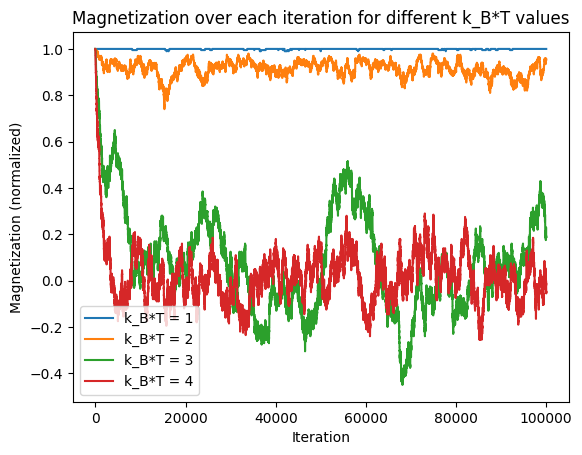

In [208]:
# Define parameters
kB_T_vals = np.array([1,2,3,4])
n = 20 # number of rows and columns for the grid (square array)
N = n*n # generate N samples (400)
n_grids = 100000 # number of configurations

M = np.zeros((len(kB_T_vals), n_grids))
for ind, kBT in enumerate(kB_T_vals):
    M[ind], _ = get_M(n, N, n_grids, kBT) # get magnetization chain given current kBT value
    plt.plot(M[ind]/N, label=f'k_B*T = {kBT}')

# Remove the first part of the chain (burn-in)
# M = M[n_grids//20:]

plt.xlabel('Iteration')
plt.ylabel('Magnetization (normalized)')
plt.title('Magnetization over each iteration for different k_B*T values')
plt.legend()
plt.show()

From the plot above, we can see that there is indeed a visible burn-in phase. Indeed, in the first ~$20$% of the plot, we see that for higher temperatures the magnetization values drop significantly from their initial value of 1 (from a +1 spin only configuration), and eventually stablize closer to 0. This is because we are accepting steps for spin flips that will gradually get us towards the expected solution, which eventually gets us further from our inital guess (the initial chosen configuration). Usually, we want to ignore this first part of the values when analyzing the results, in order to consider only the values that are unaffected by our initial arbitrary guess. In the above plot, we see that the burn-in phase appears a lot more prominent for higher temperatures ($k_BT = 3$ and $k_BT = 4$), whereas the lower temperatures appear to remain closer to their initial magnetizations throughout all iterations. 

This actually reproduces what we expect from the Ising model quite well. Indeed, below a critical temperature, thermal agitation is low enough that spins can align spontaneously into a net magnetization, which explains the stabilization near $M = 1$ for $k_BT = 1$ and $k_BT = 2$. However, when the temperature gets high enough, thermal noise dominates, and magnetization vanishes. From the plot above, we can see that this phase transition occurs between $k_BT = 2$ and $k_BT = 3$. Also, the large fluctuations that are apparent in the two curves past the phase transition can be attributed to the dominating thermal noise. We can in fact see that as the temperature increases, the fluctuations in the curves increases as well, for this particular reason.

Part c)

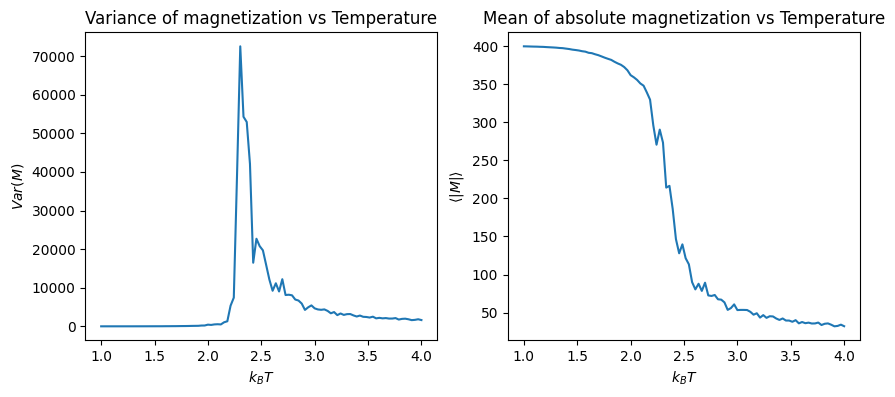

In [ ]:
# Define parameters
kB_T_vals = np.linspace(1, 4, 100)
n = 20 # number of rows and columns for the grid (square array)
N = n*n # generate N samples (400)
n_grids = 1000000 # number of configurations

# Initialize empty arrays for the variance and mean of M
var_M = np.zeros(len(kB_T_vals))
mean_M = np.zeros(len(kB_T_vals))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# Get magnetization array for each temperature in kB_T_vals
for ind, kBT in enumerate(kB_T_vals):
    M, _ = get_M(n, N, n_grids, kBT)
    M = M[n_grids//10:] # ignore the burn-in phase
    var_M[ind] = np.var(M) # calculate variance of M and add to our array
    mean_M[ind] = np.mean(np.abs(M)) # calculate mean of |M| and add to our array

# Plotting

# Variance vs Temperature
ax1.plot(kB_T_vals, var_M)
ax1.set_xlabel(r'$k_BT$')
ax1.set_ylabel(r'$Var(M)$')
ax1.set_title('Variance of magnetization vs Temperature')

# Mean magnetization vs Temperature
ax2.plot(kB_T_vals, mean_M)
ax2.set_xlabel(r'$k_BT$')
ax2.set_ylabel(r'$\langle |M| \rangle$')
ax2.set_title('Mean of absolute magnetization vs Temperature')

plt.show()

From the two plots above, we can indeed see the expected behaviour for the phase transition. Indeed, we can see that during the phase transition (which appears to be around $k_BT \approx 2.5$ from the plots), the variance of M shoots up, signaling large fluctuations in M, and then stabilizes again near 0 (even though it is still a lot higher than 0 given the scale of the plot's y axis, but relatively to the maximum variance it is a lot smaller). In addition, in the mean absolute magnetization plot, we see a significant drop around $k_BT = 2.5$ (around the phase transition). This makes sense, because as discussed in part b), when the temperature gets high enough, the magnetization (which starts at 400, given that all of the 400 spins are +1 at the beginning) vanishes since thermal noise dominates (therefore it is expected that the magnetization tends towards 0, with some noise from the large fluctuations observed).